# 23CSE301 — ML Capstone — Review 2: Clustering Track
## Track: Gig Economy / Rider–Driver Earnings & Burnout
### Dataset: `chicago_taxi_sample.csv` (same dataset as the regression & classification notebook)

**Problem statement:** without using any labels, can we discover natural groups of *driver-days* (one taxi on one
date) based on how the driver worked — how many trips, how far, how fast, at night or on weekends, how many areas
they covered, how much they earned and how customers paid? We then check, **only after the clusters are fitted**,
how these groups relate to the `burnout_risk` tiers (Low / Medium / High) defined in Review 1.

**Required algorithms (guideline 3.3):** 1. K-Means (Elbow curve to choose *k*), 2. Agglomerative Hierarchical
Clustering (Dendrogram + comparison of linkage strategies).
**Required metrics:** Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index for all algorithms.
**Required visualisations:** Elbow curve, Dendrogram, PCA (2 components) scatter for every algorithm; t-SNE (encouraged).

### Team ownership (suggested — edit to match your team)
| Member | Responsible for |
|---|---|
| **Member 1** | Shared preprocessing for clustering + K-Means (Elbow, fitting, profiling) |
| **Member 2** | Agglomerative clustering (Dendrogram, linkage comparison) + PCA / t-SNE visualisations |
| **All** | Evaluation table and post-hoc comparison with `burnout_risk` (any member may be asked in the viva) |

`random_state = 42` is used everywhere for reproducibility.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Load the dataset
The same raw trip-level file as Review 1. To use the **full dataset**, change `DATA_PATH` (same column names).

In [2]:
DATA_PATH = "chicago_taxi_sample.csv"
for candidate in [DATA_PATH, f"data/{DATA_PATH}", f"../data/{DATA_PATH}"]:
    if Path(candidate).exists():
        DATA_PATH = candidate
        break

df_raw = pd.read_csv(DATA_PATH)
print("Reading:", DATA_PATH)
print("Shape:", df_raw.shape)
print("\nMissing values per column (top 8):\n", df_raw.isna().sum().sort_values(ascending=False).head(8))

Reading: ../data/chicago_taxi_sample.csv
Shape: (33103, 19)

Missing values per column (top 8):
 dropoff_community_area    3596
dropoff_longitude         3481
dropoff_latitude          3481
pickup_community_area     2739
pickup_longitude          2736
pickup_latitude           2736
trip_seconds                 5
trip_end_timestamp           3
dtype: int64


## 2. Preprocessing — same cleaning and driver-day aggregation as Review 1
These two functions repeat the Review 1 steps (B1 cleaning, B3 feature engineering, driver-day aggregation) so this
notebook runs on its own. Keeping them identical means the clustering works on **exactly the same driver-days** as the
classification models.

* **Missing values:** trips missing core fields (timestamps, duration, distance, fare, community areas, taxi id) are
  dropped, because filling in a trip's duration or fare would invent data; missing `company` / `payment_type` become
  an explicit `"Unknown"` category.
* **Duplicates** (`unique_key`) are dropped; **impossible trips** (zero duration, negative distance/fare) are removed;
  extreme values are capped at Q3 + 3×IQR.

In [3]:
def clean_trips(df_raw):
    """Review 1 B1 + B3: clean trip-level rows and add time/speed features."""
    df = df_raw.drop_duplicates(subset=["unique_key"]).copy()
    core_cols = ["trip_start_timestamp", "trip_end_timestamp", "trip_seconds", "trip_miles",
                 "trip_total", "fare", "pickup_community_area", "dropoff_community_area", "taxi_id"]
    df = df.dropna(subset=core_cols)
    df["company"] = df["company"].fillna("Unknown")
    df["payment_type"] = df["payment_type"].fillna("Unknown")
    df = df[(df["trip_seconds"] > 0) & (df["trip_miles"] >= 0) & (df["trip_total"] >= 0)]
    for col in ["trip_total", "trip_miles", "trip_seconds"]:
        q1, q3 = df[col].quantile([0.25, 0.75])
        df[col] = df[col].clip(upper=q3 + 3 * (q3 - q1))

    df["trip_start_timestamp"] = pd.to_datetime(df["trip_start_timestamp"], errors="coerce")
    df = df.dropna(subset=["trip_start_timestamp"])
    df["pickup_hour"] = df["trip_start_timestamp"].dt.hour
    df["trip_date"] = df["trip_start_timestamp"].dt.date
    df["is_weekend"] = df["trip_start_timestamp"].dt.dayofweek.isin([5, 6]).astype(int)
    df["is_night"] = ((df["pickup_hour"] >= 22) | (df["pickup_hour"] < 5)).astype(int)
    speed = (df["trip_miles"] / (df["trip_seconds"] / 3600)).replace([np.inf, -np.inf], np.nan)
    df["trip_speed_mph"] = speed.fillna(speed.median()).clip(upper=80)
    return df


def build_driver_days(df, min_trips=2):
    """Review 1 aggregation: one row per (taxi_id, date) + the burnout_risk label (kept aside, not used for fitting)."""
    def mode_or_unknown(s):
        m = s.mode()
        return m.iloc[0] if len(m) else "Unknown"

    agg_full = df.groupby(["taxi_id", "trip_date"]).agg(
        trip_count=("unique_key", "count"),
        total_miles=("trip_miles", "sum"),
        total_duration_sec=("trip_seconds", "sum"),
        avg_speed_mph=("trip_speed_mph", "mean"),
        pct_night_trips=("is_night", "mean"),
        pct_weekend_trips=("is_weekend", "mean"),
        num_unique_pickup_areas=("pickup_community_area", "nunique"),
        num_unique_dropoff_areas=("dropoff_community_area", "nunique"),
        total_earnings=("trip_total", "sum"),
        dominant_payment_type=("payment_type", mode_or_unknown),
    ).reset_index()
    agg = agg_full[agg_full["trip_count"] >= min_trips].reset_index(drop=True)
    if len(agg) < 30:   # same fallback as Review 1 for very small samples
        agg = agg_full.reset_index(drop=True)
    agg["total_hours"] = agg["total_duration_sec"] / 3600
    agg["burnout_risk"] = pd.qcut(agg["total_hours"].rank(method="first"), q=3, labels=["Low", "Medium", "High"])
    top3 = agg["dominant_payment_type"].value_counts().head(3).index
    agg["dominant_payment_type"] = agg["dominant_payment_type"].where(agg["dominant_payment_type"].isin(top3), "Other")
    return agg


trips = clean_trips(df_raw)
driver_days = build_driver_days(trips)
print("Clean trips:", trips.shape, "| driver-days:", driver_days.shape)

# Agglomerative clustering, silhouette and t-SNE all scale roughly with n^2 in memory/time. On the FULL dataset we
# therefore cluster a random subset of at most MAX_CLUSTER_ROWS driver-days (no effect on the ~850-row sample).
MAX_CLUSTER_ROWS = 10000
if len(driver_days) > MAX_CLUSTER_ROWS:
    print(f"Randomly keeping {MAX_CLUSTER_ROWS} of {len(driver_days)} driver-days (random_state=42).")
    driver_days = driver_days.sample(n=MAX_CLUSTER_ROWS, random_state=RANDOM_STATE).reset_index(drop=True)
driver_days.head()

Clean trips: (28426, 24) | driver-days: (848, 14)


,taxi_id,trip_date,trip_count,total_miles,total_duration_sec,avg_speed_mph,pct_night_trips,pct_weekend_trips,num_unique_pickup_areas,num_unique_dropoff_areas,total_earnings,dominant_payment_type,total_hours,burnout_risk
0,0083fcde0fb490b4ec424c63d1d750378f6ad11154d1d4...,2019-10-31,2,0.1,960.0,0.200000,0.0,0.0,2,2,15.25,Cash,0.266667,Low
1,0300862a19483bcacac6176544abf331b8a3d41ec6efda...,2019-01-09,2,0.1,840.0,0.272727,0.0,0.0,2,2,14.50,Cash,0.233333,Low
2,0423b61dd9d4f4da3f4490e3dfed085a321aa78d527286...,2019-04-15,2,0.0,1080.0,0.000000,0.0,0.0,1,2,18.50,Cash,0.300000,Medium
3,045270ae331ab61646c36aaf542de0077e97a5b0294e29...,2019-02-28,2,2.6,840.0,10.500000,0.5,0.0,2,2,17.25,Cash,0.233333,Low
4,0508ec6583a6fde6f3cc9d39f86c584452ca03fd293e02...,2019-04-05,2,4.8,1500.0,10.500000,0.0,0.0,2,1,23.00,Cash,0.416667,Medium


### 2.1 Choosing the clustering features
* **Used:** the 8 numeric workload/behaviour/earnings features and the categorical `dominant_payment_type` —
  the same inputs the classifiers used.
* **Not used:** `total_hours` / `total_duration_sec` and `burnout_risk`. `burnout_risk` is a label, so it must not
  influence fitting (guideline 3.3); `total_hours` is the quantity that label was built from. Leaving both out lets us
  ask a fair question afterwards: *do clusters found without hours still line up with burnout tiers?*
* `taxi_id` / `trip_date` are identifiers, not behaviour, so they are excluded.

In [4]:
cluster_numeric = ["trip_count", "total_miles", "avg_speed_mph", "pct_night_trips", "pct_weekend_trips",
                   "num_unique_pickup_areas", "num_unique_dropoff_areas", "total_earnings"]
cluster_categorical = ["dominant_payment_type"]

X_raw = driver_days[cluster_numeric + cluster_categorical].copy()
y_burnout = driver_days["burnout_risk"].copy()      # used ONLY after fitting, for interpretation

print("Missing values in clustering features:\n", X_raw.isna().sum())
print("\nSkewness of numeric features:\n", X_raw[cluster_numeric].skew().round(2))

Missing values in clustering features:
 trip_count                  0
total_miles                 0
avg_speed_mph               0
pct_night_trips             0
pct_weekend_trips           0
num_unique_pickup_areas     0
num_unique_dropoff_areas    0
total_earnings              0
dominant_payment_type       0
dtype: int64

Skewness of numeric features:
 trip_count                  5.03
total_miles                 1.66
avg_speed_mph               0.17
pct_night_trips             1.79
pct_weekend_trips           1.55
num_unique_pickup_areas    -0.37
num_unique_dropoff_areas   -0.77
total_earnings              1.78
dtype: float64


### 2.2 Log-transform skewed features
K-Means and Ward linkage use (squared) Euclidean distance, so a few very large values can dominate. `trip_count`,
`total_miles` and `total_earnings` are counts/amounts with long right tails, so we apply `log1p` (= log(1 + x), safe at 0) to reduce their skew.
This is a fixed formula with nothing learned from the data, so it cannot leak information between splits.

Skewness after log1p:
 trip_count        4.88
total_miles       0.15
total_earnings    0.66
dtype: float64


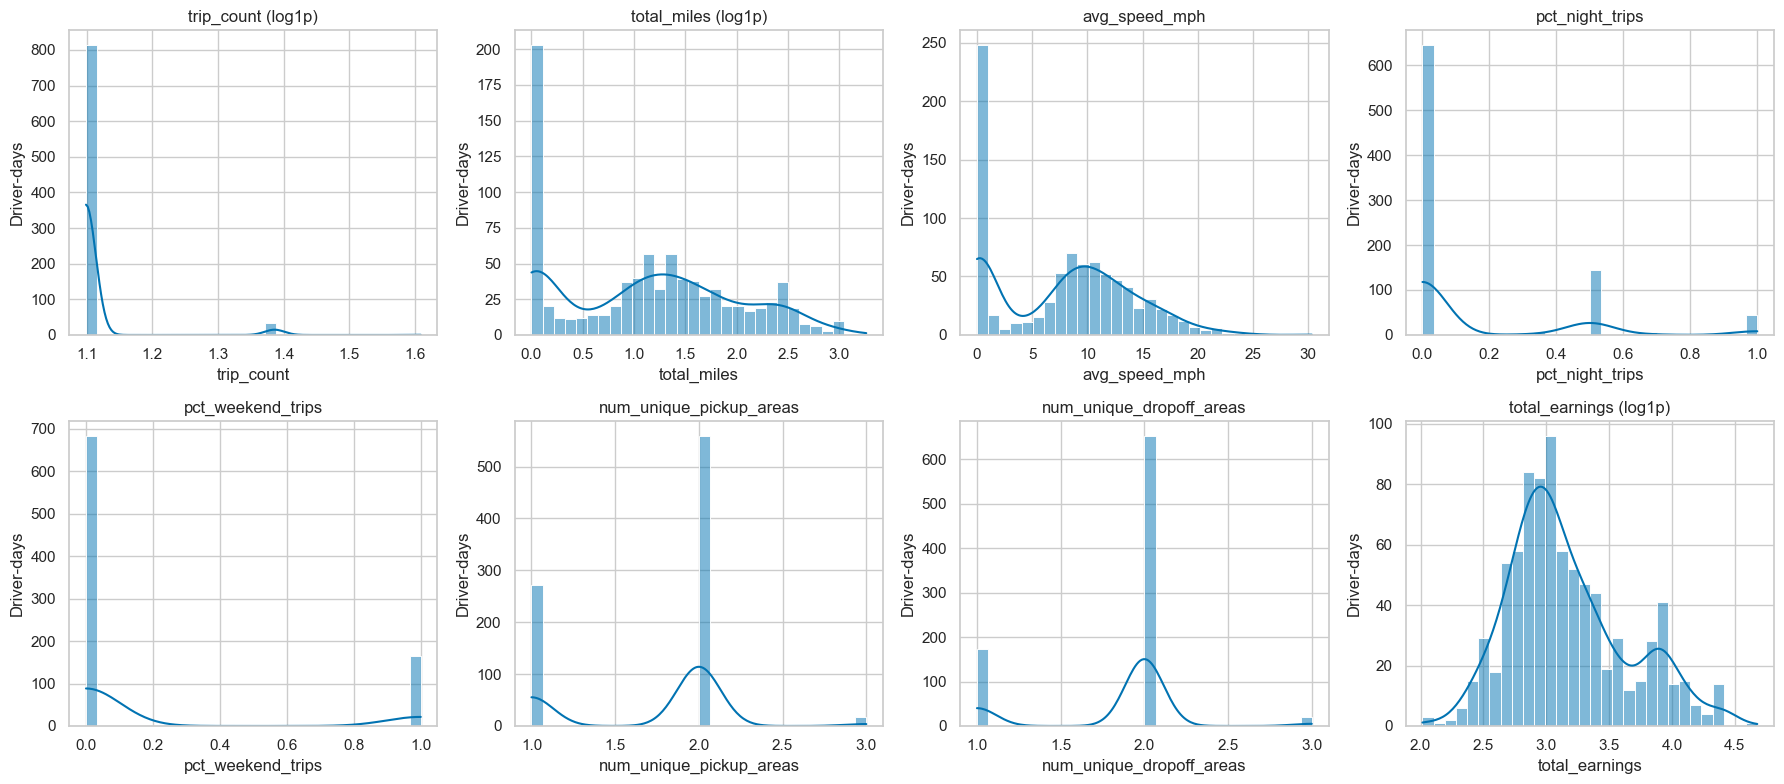

In [5]:
LOG_FEATURES = ["trip_count", "total_miles", "total_earnings"]
X_log = X_raw.copy()
X_log[LOG_FEATURES] = np.log1p(X_log[LOG_FEATURES])
print("Skewness after log1p:\n", X_log[LOG_FEATURES].skew().round(2))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), cluster_numeric):
    sns.histplot(X_log[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"{col}" + (" (log1p)" if col in LOG_FEATURES else ""))
    ax.set_xlabel(col)
    ax.set_ylabel("Driver-days")
plt.tight_layout()
plt.savefig("clu_feature_distributions.png", bbox_inches="tight")
plt.show()

### 2.3 Train/test split, imputation, encoding, scaling (fitted on the training split only)
Guidelines 7.1–7.2 require a consistent 80:20 split and transformers fitted on the training split only. Clusters are
**fitted on the 80% training split**; the 20% test split is then assigned to those clusters to check that the
structure holds on unseen driver-days. (The split is not stratified, because stratifying would use the labels.)

* `SimpleImputer` (median for numeric, most-frequent for categorical) — the sample has no gaps after aggregation, but
  this keeps the notebook safe on the full dataset.
* `OneHotEncoder` for `dominant_payment_type`; `StandardScaler` so every numeric feature contributes equally to distances.

In [6]:
X_train_raw, X_test_raw, burnout_train, burnout_test = train_test_split(
    X_log, y_burnout, test_size=0.2, random_state=RANDOM_STATE)

num_imputer = SimpleImputer(strategy="median").fit(X_train_raw[cluster_numeric])
cat_imputer = SimpleImputer(strategy="most_frequent").fit(X_train_raw[cluster_categorical])
scaler = StandardScaler().fit(num_imputer.transform(X_train_raw[cluster_numeric]))
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(cat_imputer.transform(X_train_raw[cluster_categorical]))

def transform(frame):
    """Apply the train-fitted imputers, scaler and encoder to any split."""
    num = scaler.transform(num_imputer.transform(frame[cluster_numeric]))
    cat = encoder.transform(cat_imputer.transform(frame[cluster_categorical]))
    return np.hstack([num, cat])

feature_names = cluster_numeric + list(encoder.get_feature_names_out(cluster_categorical))
X_train = transform(X_train_raw)
X_test = transform(X_test_raw)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Features:", feature_names)

Train: (678, 11) | Test: (170, 11)
Features: ['trip_count', 'total_miles', 'avg_speed_mph', 'pct_night_trips', 'pct_weekend_trips', 'num_unique_pickup_areas', 'num_unique_dropoff_areas', 'total_earnings', 'dominant_payment_type_Cash', 'dominant_payment_type_Credit Card', 'dominant_payment_type_No Charge']


### Evaluation helper
* **Silhouette Score** (−1 to 1, higher is better): how much closer each point is to its own cluster than to the nearest other cluster.
* **Davies–Bouldin Index** (≥ 0, lower is better): average similarity between each cluster and its most similar cluster.
* **Calinski–Harabasz Index** (≥ 0, higher is better): between-cluster spread divided by within-cluster spread.
  It grows with the number of points, so compare algorithms **on the same split** — the test value (170 rows) is naturally
  much smaller than the training value (678 rows).

In [7]:
def cluster_metrics(X, labels):
    """Silhouette, Davies-Bouldin and Calinski-Harabasz for one labelling (needs >= 2 clusters)."""
    if len(np.unique(labels)) < 2:
        return {"Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    return {"Silhouette": silhouette_score(X, labels, random_state=RANDOM_STATE),
            "Davies-Bouldin": davies_bouldin_score(X, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X, labels)}

def nearest_centroid_labels(X_new, X_fit, labels_fit):
    """Assign new points to the closest cluster centre (used for Agglomerative, which has no .predict())."""
    clusters = np.unique(labels_fit)
    centres = np.vstack([X_fit[labels_fit == c].mean(axis=0) for c in clusters])
    dists = ((X_new[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
    return clusters[dists.argmin(axis=1)]

## 3. Algorithm 1 — K-Means Clustering  `# Owner: Member 1`
### 3.1 Elbow curve (inertia vs. k) to choose k
Inertia = sum of squared distances from each point to its cluster centre; it always falls as *k* grows, so we look for
the "elbow" where adding clusters stops helping much. To make the choice objective rather than by eye, the elbow is
taken as the *k* whose point lies **farthest from the straight line joining the first and last points** of the curve
(the "knee" method). The silhouette score per *k* is shown alongside as a second opinion.

In [8]:
# Owner: Member 1
K_RANGE = range(2, 11)
inertias, silhouettes = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train, km.labels_, random_state=RANDOM_STATE))

# Knee: normalise both axes to 0-1, then find the point farthest from the line between the end points
ks = np.array(list(K_RANGE), dtype=float)
x_n = (ks - ks.min()) / (ks.max() - ks.min())
y_n = (np.array(inertias) - min(inertias)) / (max(inertias) - min(inertias))
distance_to_chord = np.abs(y_n - (1 - x_n))   # chord runs from (0, 1) to (1, 0)
BEST_K = int(ks[distance_to_chord.argmax()])

elbow_table = pd.DataFrame({"k": list(K_RANGE), "Inertia": inertias, "Silhouette": silhouettes})
print("Chosen k from the elbow (knee) method:", BEST_K)
elbow_table.round(4)

Chosen k from the elbow (knee) method: 5


,k,Inertia,Silhouette
0,2,4671.3414,0.1851
1,3,3924.5115,0.2001
2,4,3386.7868,0.2164
3,5,2998.1894,0.2222
4,6,2755.3271,0.1986
5,7,2469.7624,0.2326
6,8,2291.1348,0.2403
7,9,2181.0771,0.2475
8,10,2067.9055,0.2641


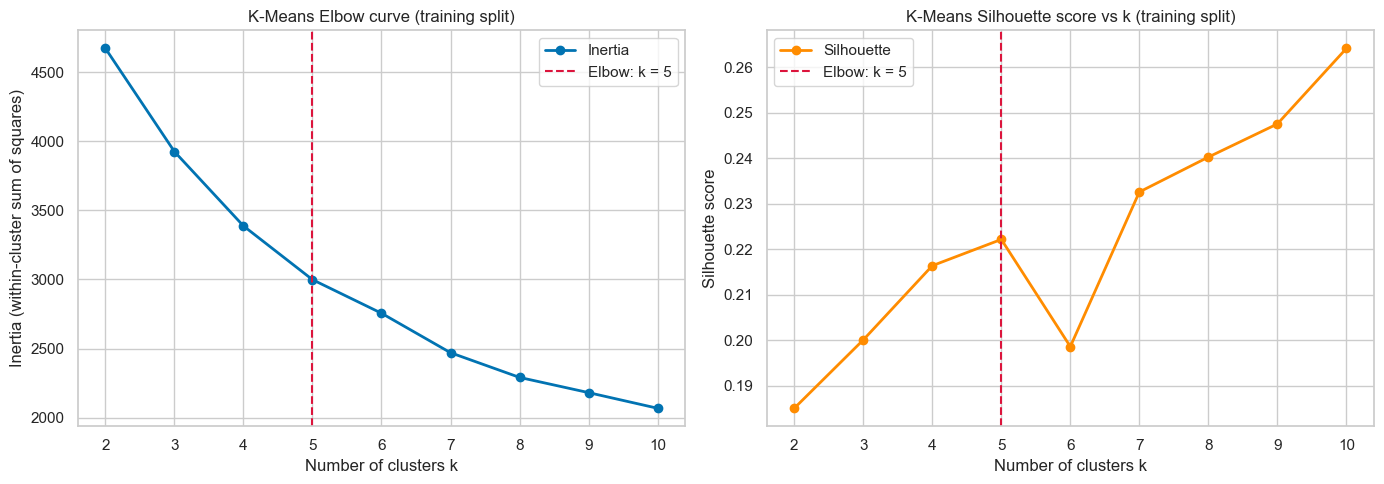

In [9]:
# Owner: Member 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(K_RANGE), inertias, "o-", lw=2, label="Inertia")
axes[0].axvline(BEST_K, color="crimson", ls="--", label=f"Elbow: k = {BEST_K}")
axes[0].set_title("K-Means Elbow curve (training split)")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].legend()

axes[1].plot(list(K_RANGE), silhouettes, "o-", lw=2, color="darkorange", label="Silhouette")
axes[1].axvline(BEST_K, color="crimson", ls="--", label=f"Elbow: k = {BEST_K}")
axes[1].set_title("K-Means Silhouette score vs k (training split)")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.savefig("clu_kmeans_elbow_silhouette.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: where does the elbow bend? Does the silhouette curve agree with that k, or does it prefer a different one? Which would you defend in the viva and why?]_

### 3.2 Fit K-Means with the chosen k

In [10]:
# Owner: Member 1
kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE).fit(X_train)
km_train_labels = kmeans.labels_
km_test_labels = kmeans.predict(X_test)          # unseen driver-days -> nearest learned centre
print("K-Means cluster sizes (train):", np.bincount(km_train_labels))
print("K-Means cluster sizes (test): ", np.bincount(km_test_labels, minlength=BEST_K))

K-Means cluster sizes (train): [200 113  26 115 224]
K-Means cluster sizes (test):  [63 15  8 33 51]


## 4. Algorithm 2 — Agglomerative Hierarchical Clustering  `# Owner: Member 2`
### 4.1 Dendrogram (Ward linkage)
Agglomerative clustering starts with every driver-day as its own cluster and repeatedly merges the two closest
clusters. The dendrogram records every merge; the height of a merge is the distance at which it happened.
Cutting the tree with a horizontal line gives the clusters. We draw the cut that produces the **same k as K-Means**,
so the two algorithms are compared on equal terms. (Only the last 30 merges are drawn so the plot is readable.)

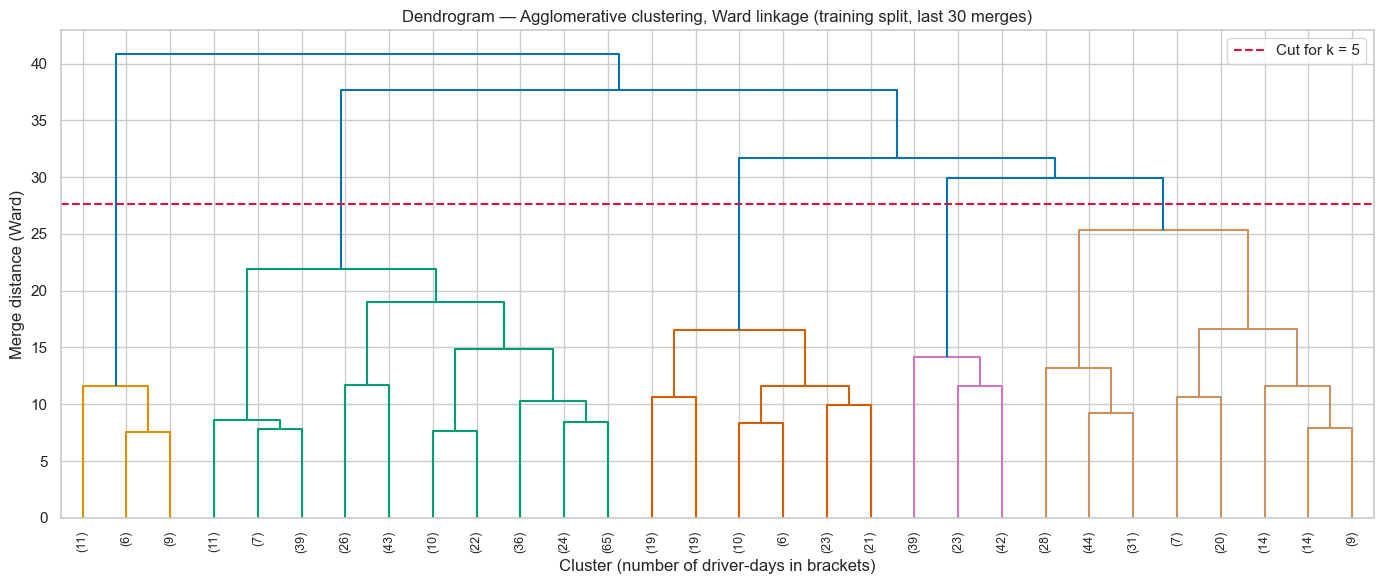

In [11]:
# Owner: Member 2
Z_ward = linkage(X_train, method="ward")
# Height between the merges that leave BEST_K and BEST_K-1 clusters -> a cut here gives exactly BEST_K clusters
cut_height = (Z_ward[-BEST_K, 2] + Z_ward[-BEST_K + 1, 2]) / 2

plt.figure(figsize=(14, 6))
dendrogram(Z_ward, truncate_mode="lastp", p=30, color_threshold=cut_height,
           show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9)
plt.axhline(cut_height, color="crimson", ls="--", label=f"Cut for k = {BEST_K}")
plt.title("Dendrogram — Agglomerative clustering, Ward linkage (training split, last 30 merges)")
plt.xlabel("Cluster (number of driver-days in brackets)")
plt.ylabel("Merge distance (Ward)")
plt.legend()
plt.tight_layout()
plt.savefig("clu_dendrogram_ward.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: is there a large vertical gap in the dendrogram (a natural place to cut)? Does it agree with the K-Means elbow?]_

### 4.2 Comparing linkage strategies
* **Ward:** merges the pair that increases total within-cluster variance the least (similar goal to K-Means).
* **Complete:** distance between clusters = their two *farthest* points.
* **Average:** mean distance over all pairs of points.
* **Single:** distance between the two *closest* points (prone to "chaining" into one giant cluster).

All four use the same k. **Selection rule (two steps):**
1. *Eligibility:* a linkage is only usable if its largest cluster holds **at most 75%** of the training driver-days.
   A result with one giant cluster plus a few tiny ones has not really split the data into groups, yet it can still get a
   high Silhouette score (the giant cluster is far from the few outliers), so metrics alone would be misleading.
2. *Ranking:* eligible linkages are ranked on each metric (Silhouette ↑, Calinski–Harabasz ↑, Davies–Bouldin ↓) and the one
   with the best **average rank** is kept, so no single metric decides alone.

In [12]:
# Owner: Member 2
LINKAGES = ["ward", "complete", "average", "single"]
linkage_rows, agg_train_labels_by_linkage = [], {}
for method in LINKAGES:
    model = AgglomerativeClustering(n_clusters=BEST_K, linkage=method).fit(X_train)
    agg_train_labels_by_linkage[method] = model.labels_
    sizes = sorted(np.bincount(model.labels_), reverse=True)
    linkage_rows.append({"Linkage": method, **cluster_metrics(X_train, model.labels_),
                         "Cluster sizes (train)": sizes,
                         "Largest cluster share": sizes[0] / len(model.labels_)})

MAX_LARGEST_SHARE = 0.75
linkage_table = pd.DataFrame(linkage_rows)
linkage_table["Eligible (largest share <= 75%)"] = linkage_table["Largest cluster share"] <= MAX_LARGEST_SHARE
if not linkage_table["Eligible (largest share <= 75%)"].any():   # safety net: if none qualify, rank them all
    linkage_table["Eligible (largest share <= 75%)"] = True
eligible = linkage_table[linkage_table["Eligible (largest share <= 75%)"]]
ranks = pd.concat([eligible["Silhouette"].rank(ascending=False),
                   eligible["Calinski-Harabasz"].rank(ascending=False),
                   eligible["Davies-Bouldin"].rank(ascending=True)], axis=1)
linkage_table["Average rank (eligible only)"] = ranks.mean(axis=1)      # NaN for ineligible linkages
linkage_table = linkage_table.sort_values(["Eligible (largest share <= 75%)", "Average rank (eligible only)"],
                                          ascending=[False, True]).reset_index(drop=True)
BEST_LINKAGE = linkage_table.loc[0, "Linkage"]
print("Selected linkage:", BEST_LINKAGE)
linkage_table.round(4)

Selected linkage: ward


,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes (train),Largest cluster share,Eligible (largest share <= 75%),Average rank (eligible only)
0,ward,0.2321,1.4763,131.1827,"[283, 167, 104, 98, 26]",0.4174,True,1.0
1,complete,0.1645,1.6818,85.8740,"[370, 266, 16, 13, 13]",0.5457,True,2.0
2,average,0.2641,0.9709,46.3808,"[628, 25, 21, 3, 1]",0.9263,False,NaN
3,single,0.4413,0.9186,31.4008,"[652, 22, 2, 1, 1]",0.9617,False,NaN


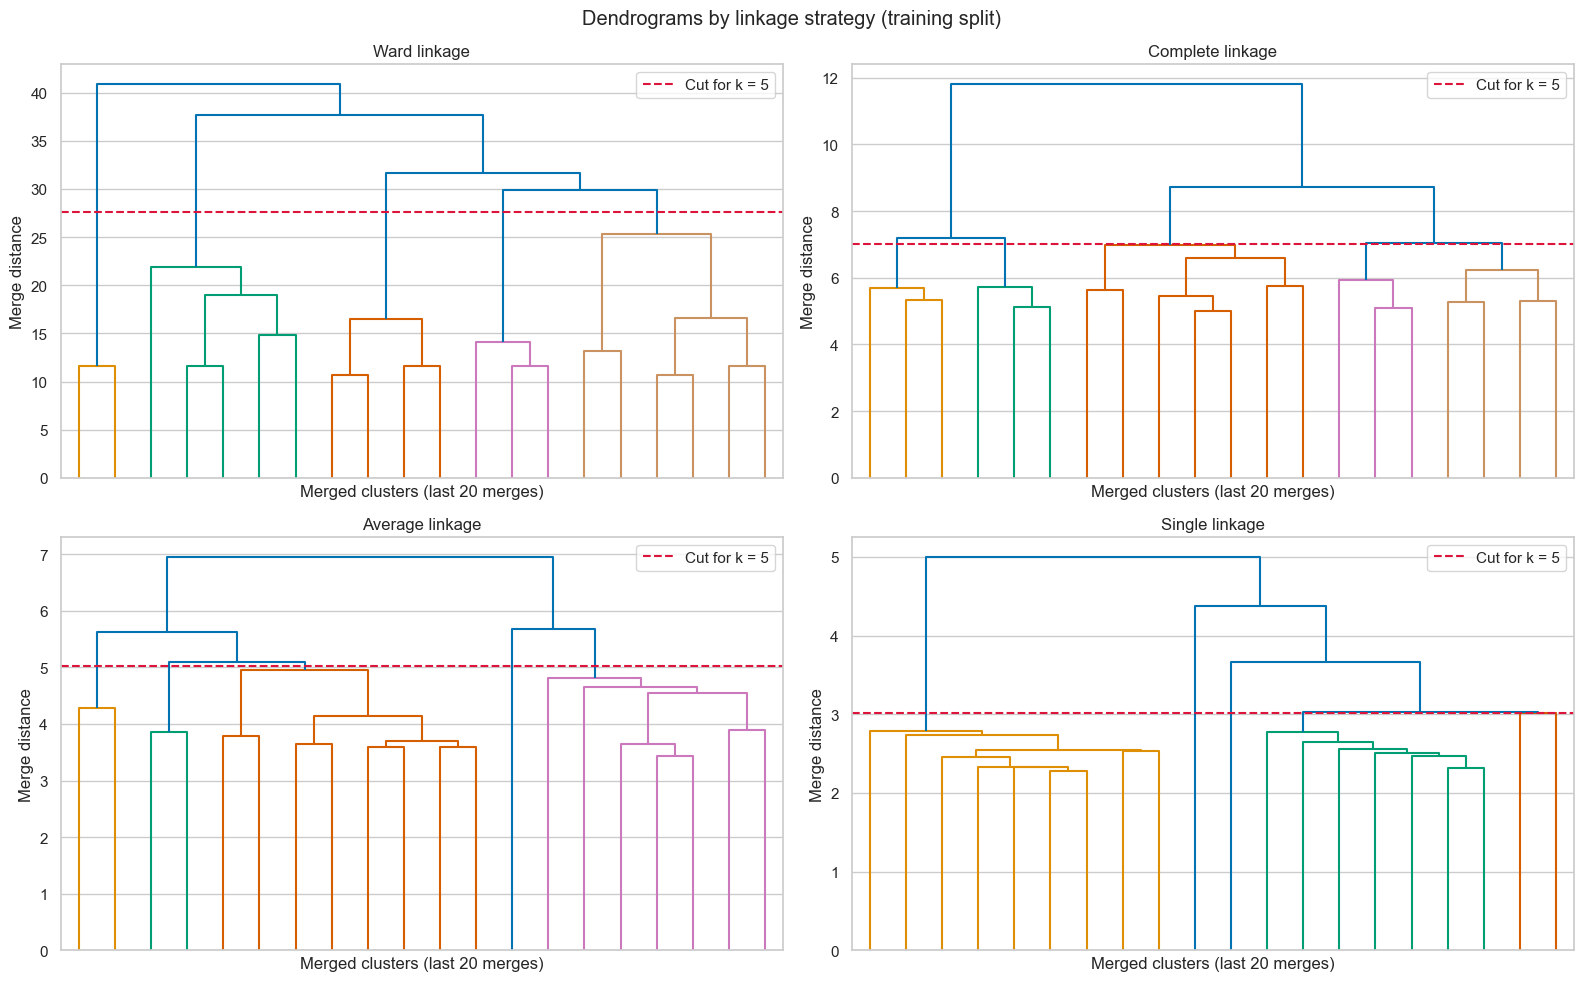

In [13]:
# Owner: Member 2 — dendrograms for all four linkage strategies, side by side
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, method in zip(axes.flatten(), LINKAGES):
    Z = Z_ward if method == "ward" else linkage(X_train, method=method)
    h = (Z[-BEST_K, 2] + Z[-BEST_K + 1, 2]) / 2
    dendrogram(Z, truncate_mode="lastp", p=20, color_threshold=h, ax=ax, no_labels=True)
    ax.axhline(h, color="crimson", ls="--", label=f"Cut for k = {BEST_K}")
    ax.set_title(f"{method.capitalize()} linkage")
    ax.set_xlabel("Merged clusters (last 20 merges)")
    ax.set_ylabel("Merge distance")
    ax.legend()
plt.suptitle("Dendrograms by linkage strategy (training split)")
plt.tight_layout()
plt.savefig("clu_dendrogram_linkage_comparison.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: which linkage gives balanced clusters and which collapses into one large cluster (look at the cluster sizes)? Why does single linkage behave this way?]_

### 4.3 Final Agglomerative model
Agglomerative clustering has no `.predict()`, so each **test** driver-day is assigned to the training cluster whose
centre (mean point) is closest — the same rule K-Means uses.

In [14]:
# Owner: Member 2
agg_model = AgglomerativeClustering(n_clusters=BEST_K, linkage=BEST_LINKAGE).fit(X_train)
agg_train_labels = agg_model.labels_
agg_test_labels = nearest_centroid_labels(X_test, X_train, agg_train_labels)
print(f"Agglomerative ({BEST_LINKAGE}) cluster sizes (train):", np.bincount(agg_train_labels))
print(f"Agglomerative ({BEST_LINKAGE}) cluster sizes (test): ", np.bincount(agg_test_labels, minlength=BEST_K))

Agglomerative (ward) cluster sizes (train): [167  98 283  26 104]
Agglomerative (ward) cluster sizes (test):  [44 32 71  8 15]


## 5. Evaluation — Silhouette, Davies–Bouldin and Calinski–Harabasz for both algorithms

In [15]:
results = []
for name, tr, te in [("K-Means", km_train_labels, km_test_labels),
                     (f"Agglomerative ({BEST_LINKAGE})", agg_train_labels, agg_test_labels)]:
    for split, X_split, labels in [("train (fitted)", X_train, tr), ("test (assigned)", X_test, te)]:
        results.append({"Algorithm": name, "k": BEST_K, "Split": split, **cluster_metrics(X_split, labels)})

cluster_comparison = pd.DataFrame(results)
cluster_comparison.to_csv("clustering_comparison.csv", index=False)
cluster_comparison.round(4)

,Algorithm,k,Split,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,5,train (fitted),0.2222,1.3954,151.5096
1,K-Means,5,test (assigned),0.2265,1.2944,41.2595
2,Agglomerative (ward),5,train (fitted),0.2321,1.4763,131.1827
3,Agglomerative (ward),5,test (assigned),0.2295,1.3259,37.5974


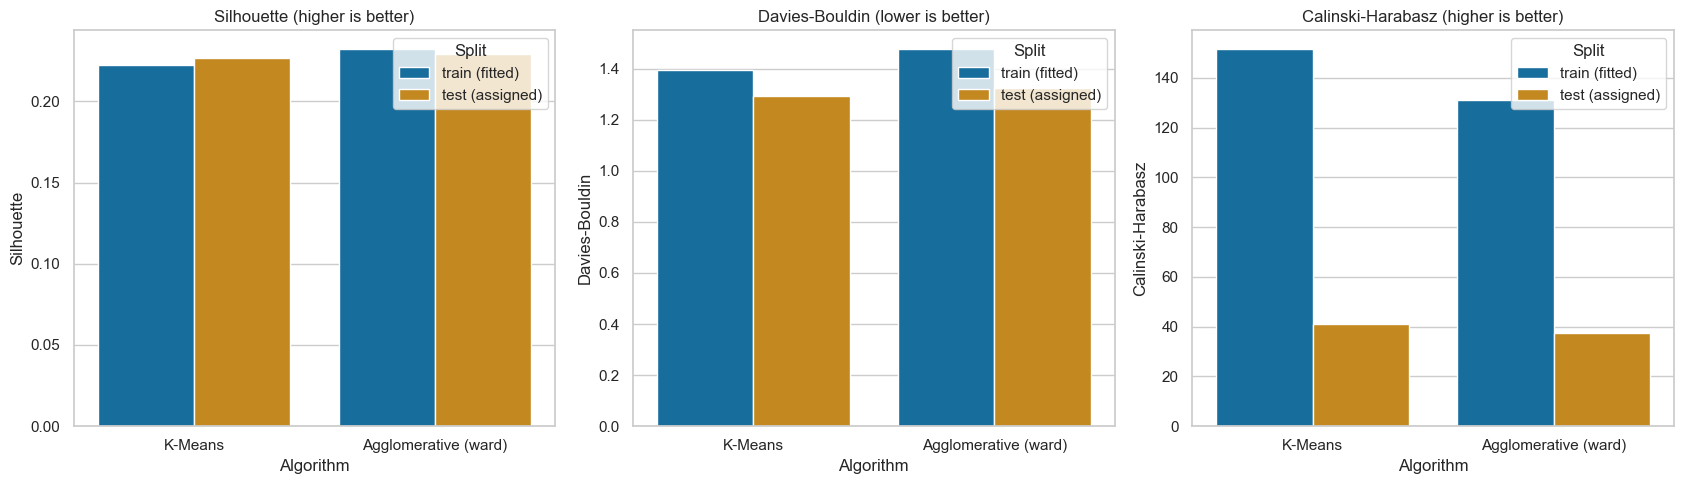

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric, better in zip(axes, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
                              ["higher is better", "lower is better", "higher is better"]):
    sns.barplot(data=cluster_comparison, x="Algorithm", y=metric, hue="Split", palette="colorblind", ax=ax)
    ax.set_title(f"{metric} ({better})")
    ax.set_xlabel("Algorithm")
    ax.set_ylabel(metric)
    ax.legend(title="Split")
plt.tight_layout()
plt.savefig("clu_metric_comparison.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: which algorithm scores better on each metric? Do the test-split scores stay close to the training scores (i.e. is the structure stable on unseen driver-days)?]_

## 6. Cluster visualisation
### 6.1 PCA — 2 principal components (mandatory, every algorithm)
PCA is fitted on the training split only and used purely for drawing; the clusters were found in the full feature space.

Variance explained: PC1 = 27.0%, PC2 = 17.6%, total = 44.6%


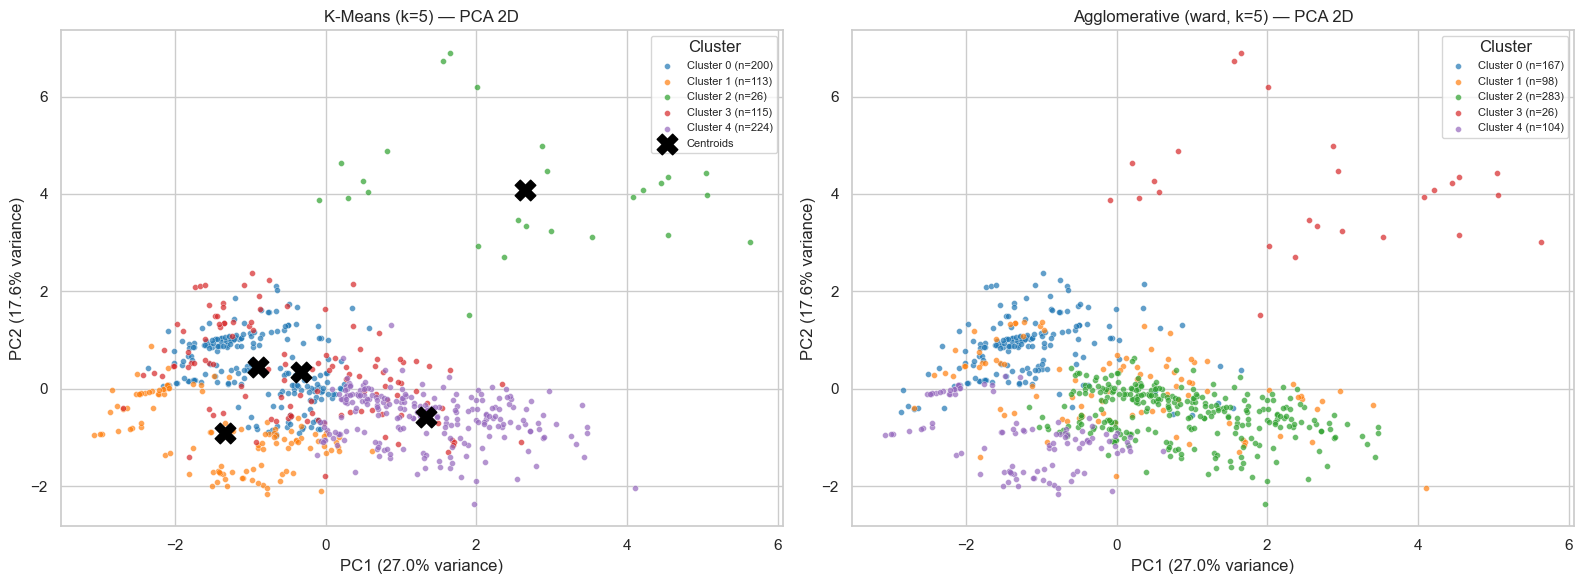

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train)
X_train_pca = pca.transform(X_train)
evr = pca.explained_variance_ratio_
print(f"Variance explained: PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}, total = {evr.sum():.1%}")

palette = sns.color_palette("tab10", BEST_K)
def scatter_clusters(ax, coords, labels, title, xlabel, ylabel):
    for c in np.unique(labels):
        mask = labels == c
        ax.scatter(coords[mask, 0], coords[mask, 1], s=18, alpha=0.7, color=palette[c],
                   edgecolor="white", linewidth=0.3, label=f"Cluster {c} (n={mask.sum()})")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(title="Cluster", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
scatter_clusters(axes[0], X_train_pca, km_train_labels, f"K-Means (k={BEST_K}) — PCA 2D",
                 f"PC1 ({evr[0]:.1%} variance)", f"PC2 ({evr[1]:.1%} variance)")
centres_pca = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(centres_pca[:, 0], centres_pca[:, 1], marker="X", s=220, color="black", label="Centroids")
axes[0].legend(title="Cluster", fontsize=8)
scatter_clusters(axes[1], X_train_pca, agg_train_labels, f"Agglomerative ({BEST_LINKAGE}, k={BEST_K}) — PCA 2D",
                 f"PC1 ({evr[0]:.1%} variance)", f"PC2 ({evr[1]:.1%} variance)")
plt.tight_layout()
plt.savefig("clu_pca_kmeans_vs_agglomerative.png", bbox_inches="tight")
plt.show()

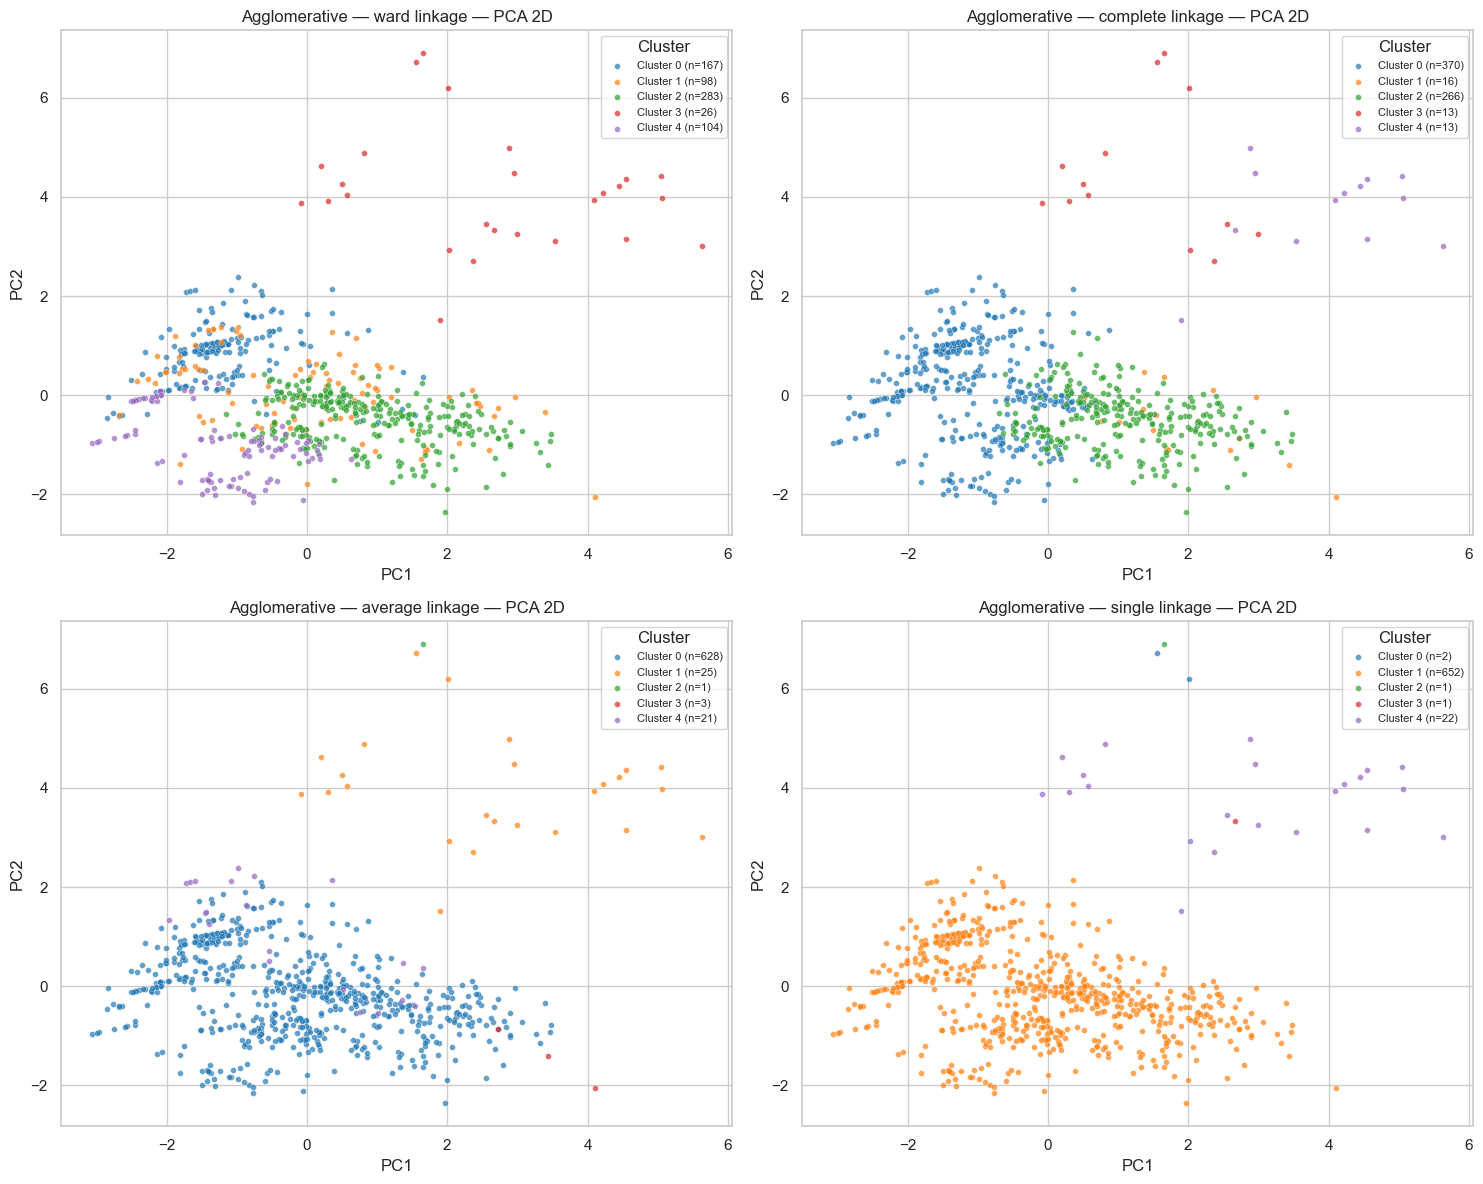

In [18]:
# PCA view of every linkage strategy (supports the linkage comparison in 4.2)
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, method in zip(axes.flatten(), LINKAGES):
    scatter_clusters(ax, X_train_pca, agg_train_labels_by_linkage[method],
                     f"Agglomerative — {method} linkage — PCA 2D", "PC1", "PC2")
plt.tight_layout()
plt.savefig("clu_pca_all_linkages.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: are the clusters visibly separated along PC1/PC2, or do they overlap? Remember PCA keeps only part of the variance (printed above).]_

### 6.2 t-SNE (encouraged; required for at least one algorithm)
t-SNE is a non-linear 2-D map that keeps *nearby* points nearby; distances between far-apart groups are not meaningful.
One embedding of the training split is computed and coloured by each algorithm's labels.

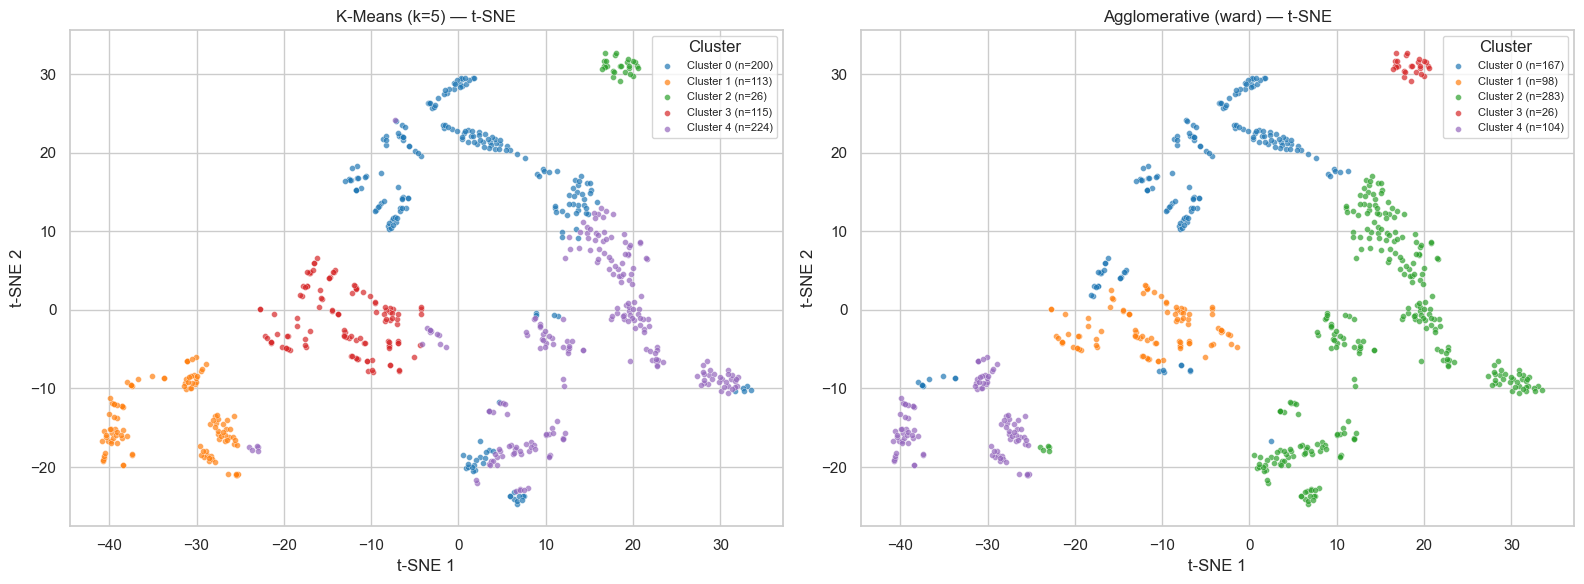

In [19]:
tsne = TSNE(n_components=2, perplexity=min(30, (len(X_train) - 1) // 3), init="pca", random_state=RANDOM_STATE)
X_train_tsne = tsne.fit_transform(X_train)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
scatter_clusters(axes[0], X_train_tsne, km_train_labels, f"K-Means (k={BEST_K}) — t-SNE", "t-SNE 1", "t-SNE 2")
scatter_clusters(axes[1], X_train_tsne, agg_train_labels, f"Agglomerative ({BEST_LINKAGE}) — t-SNE", "t-SNE 1", "t-SNE 2")
plt.tight_layout()
plt.savefig("clu_tsne_kmeans_vs_agglomerative.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: does t-SNE show clearer groups than PCA? Do K-Means and Agglomerative carve the map up the same way?]_

## 7. Interpreting the clusters
### 7.1 Cluster profiles
Mean of each original (un-scaled, un-logged) feature per cluster, so the numbers are in real units
(trips, miles, mph, $). The heatmap colours show the same means as z-scores relative to all training driver-days.

In [20]:
profile_source = X_raw.loc[X_train_raw.index, cluster_numeric].copy()
profile_source["total_hours (not used for fitting)"] = driver_days.loc[X_train_raw.index, "total_hours"]

def cluster_profile(labels):
    prof = profile_source.groupby(labels).mean()
    prof.insert(0, "size", np.bincount(labels))
    prof.index.name = "cluster"
    return prof

km_profile = cluster_profile(km_train_labels)
agg_profile = cluster_profile(agg_train_labels)
print("K-Means cluster profiles (training split, real units):")
display(km_profile.round(2))
print(f"Agglomerative ({BEST_LINKAGE}) cluster profiles (training split, real units):")
display(agg_profile.round(2))

K-Means cluster profiles (training split, real units):


,size,trip_count,total_miles,avg_speed_mph,pct_night_trips,pct_weekend_trips,num_unique_pickup_areas,num_unique_dropoff_areas,total_earnings,total_hours (not used for fitting)
cluster,,,,,,,,,,
0,200,2.00,0.79,3.14,0.11,0.00,1.65,2.00,22.41,0.35
1,113,2.00,1.55,6.02,0.09,0.00,1.60,1.00,16.89,0.28
2,26,3.04,5.64,8.62,0.18,0.19,2.42,2.62,37.76,0.56
3,115,2.00,2.35,6.98,0.33,1.00,1.61,1.78,24.10,0.34
4,224,2.00,6.92,12.98,0.09,0.04,1.75,1.97,32.66,0.51


Agglomerative (ward) cluster profiles (training split, real units):


,size,trip_count,total_miles,avg_speed_mph,pct_night_trips,pct_weekend_trips,num_unique_pickup_areas,num_unique_dropoff_areas,total_earnings,total_hours (not used for fitting)
cluster,,,,,,,,,,
0,167,2.00,0.45,1.24,0.30,0.16,1.66,1.93,25.48,0.38
1,98,2.00,3.66,8.34,0.15,1.00,1.61,1.77,27.52,0.41
2,283,2.00,5.46,11.72,0.08,0.00,1.71,1.98,27.40,0.44
3,26,3.04,5.64,8.62,0.18,0.19,2.42,2.62,37.76,0.56
4,104,2.00,1.68,6.53,0.05,0.00,1.62,1.00,17.03,0.29


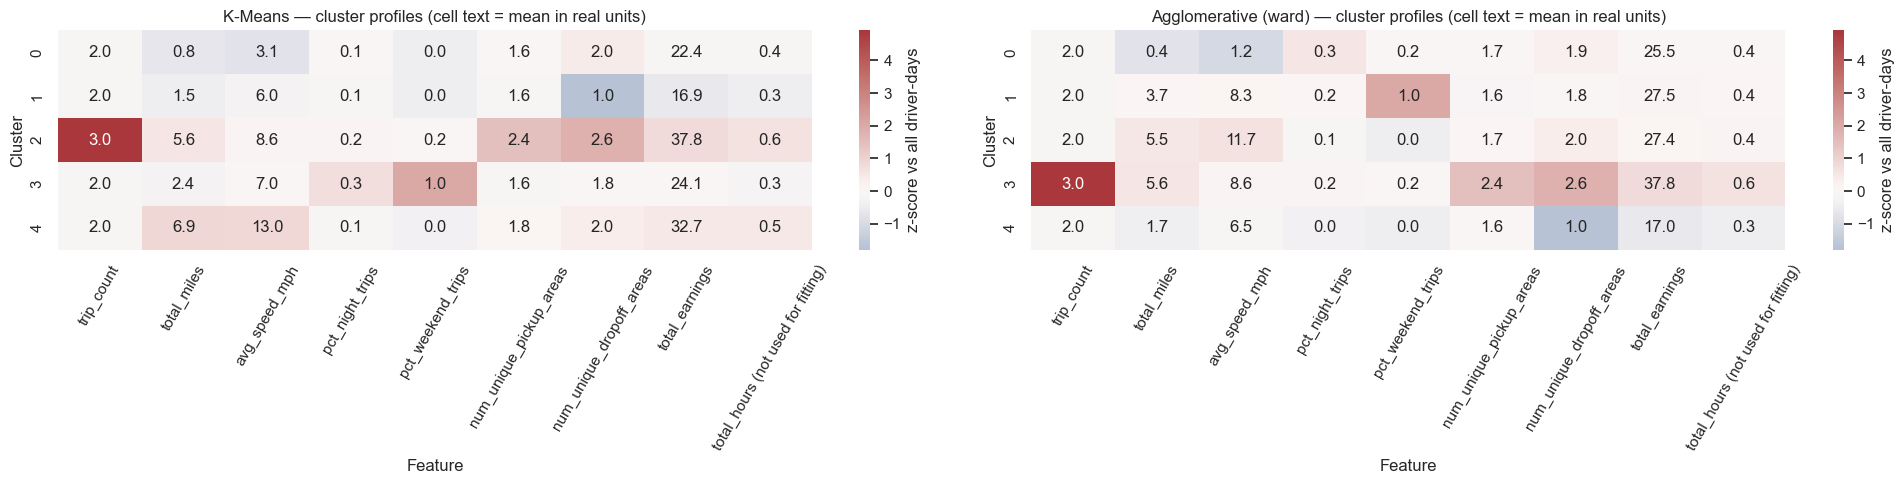

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(20, 5))
for ax, prof, title in [(axes[0], km_profile, "K-Means"), (axes[1], agg_profile, f"Agglomerative ({BEST_LINKAGE})")]:
    z = (prof.drop(columns="size") - profile_source.mean()) / profile_source.std()
    sns.heatmap(z, annot=prof.drop(columns="size").round(1), fmt="", cmap="vlag", center=0,
                cbar_kws={"label": "z-score vs all driver-days"}, ax=ax)
    ax.set_title(f"{title} — cluster profiles (cell text = mean in real units)")
    ax.set_xlabel("Feature")
    ax.set_ylabel("Cluster")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig("clu_cluster_profiles.png", bbox_inches="tight")
plt.show()

**Observation:** _[Fill in: give each cluster a short descriptive name based on its profile (e.g. "short cash trips", "long-distance high earners") and explain what kind of driver-day it represents.]_

### 7.2 Post-hoc comparison with `burnout_risk` (labels used only now, after fitting)
* **Crosstab:** share of each burnout tier inside each cluster.
* **Adjusted Rand Index (ARI)** and **Normalised Mutual Information (NMI)**: 0 ≈ no agreement beyond chance, 1 = identical
  grouping. These are not used to choose models; they only describe how the unsupervised groups relate to the label.

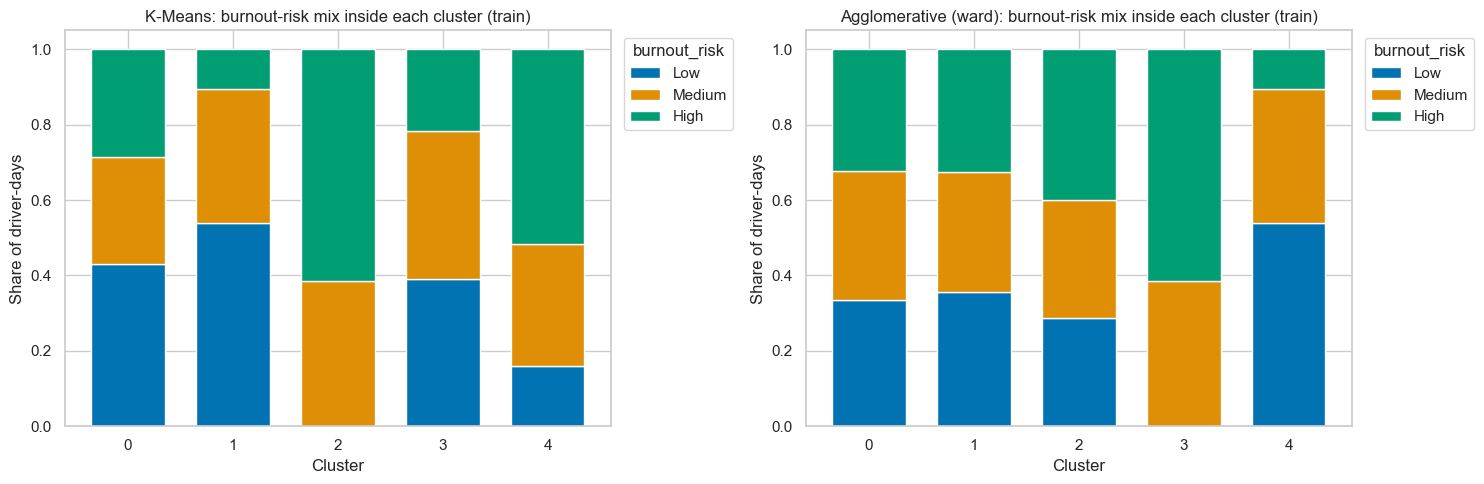

,Algorithm,ARI vs burnout_risk,NMI vs burnout_risk
0,K-Means,0.0526,0.0686
1,Agglomerative (ward),0.0142,0.0365


In [22]:
posthoc_rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (name, labels) in zip(axes, [("K-Means", km_train_labels), (f"Agglomerative ({BEST_LINKAGE})", agg_train_labels)]):
    ct = pd.crosstab(pd.Series(labels, name="Cluster"), burnout_train.values, normalize="index")[["Low", "Medium", "High"]]
    ct.plot(kind="bar", stacked=True, ax=ax, color=sns.color_palette("colorblind", 3), width=0.7)
    ax.set_title(f"{name}: burnout-risk mix inside each cluster (train)")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Share of driver-days")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="burnout_risk", bbox_to_anchor=(1.01, 1), loc="upper left")
    posthoc_rows.append({"Algorithm": name,
                         "ARI vs burnout_risk": adjusted_rand_score(burnout_train, labels),
                         "NMI vs burnout_risk": normalized_mutual_info_score(burnout_train, labels)})
plt.tight_layout()
plt.savefig("clu_posthoc_burnout_mix.png", bbox_inches="tight")
plt.show()
pd.DataFrame(posthoc_rows).round(4)

**Observation:** _[Fill in: do any clusters contain mostly High (or mostly Low) burnout-risk driver-days even though hours were never given to the algorithm? What does the ARI/NMI value say about how strongly the natural groups and the burnout tiers overlap?]_

## 8. Summary table and conclusion

In [23]:
summary = cluster_comparison[cluster_comparison["Split"] == "train (fitted)"].drop(columns="Split").merge(
    pd.DataFrame(posthoc_rows), on="Algorithm")
summary.round(4)

,Algorithm,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs burnout_risk,NMI vs burnout_risk
0,K-Means,5,0.2222,1.3954,151.5096,0.0526,0.0686
1,Agglomerative (ward),5,0.2321,1.4763,131.1827,0.0142,0.0365


**Conclusion (write this yourselves — guideline 7.5):** _[Fill in: which algorithm you would choose for grouping
driver-days and why (metrics + interpretability of profiles), what the chosen k means in practice, and one limitation
(e.g. the sample only has ~850 driver-days, most with 2 trips; PCA explains only part of the variance).]_

## Review 2 — clustering rubric checklist

| Rubric item | Max | Where it's covered |
|---|---|---|
| B1 Implementation | 4 | §3 K-Means (labels for train + test), §4 Agglomerative (4 linkages fitted, best selected, labels for train + test) — runs top-to-bottom without errors |
| B2 Evaluation metrics | 2 | §5 Silhouette, Davies–Bouldin, Calinski–Harabasz for both algorithms (train and test) + §4.2 for every linkage; Elbow curve §3.1; Dendrogram §4.1 (+ all linkages §4.2) |
| B3 Cluster visualisation | 2 | §6.1 PCA 2-D scatter for K-Means, Agglomerative and every linkage; §6.2 t-SNE for both algorithms |
| Guideline 3.3 labels | — | `burnout_risk` set aside before fitting, used only in §7.2 |
| Guideline 7.1 leakage | — | Imputers, encoder, scaler, PCA fitted on the training split only; `random_state=42` throughout |
| Guideline 7.3 plots | — | Every plot has a title, axis labels, legend where needed, `tight_layout`, colourblind palettes |